# 02 · Transfer Learning en CPU (`MobileNetV3-Small`) vs. descriptores espectrales, IC bootstrap y Few-Shot

Cinco modelos entrenados en **CPU** con las particiones oficiales de EuroSAT: **16.200** imágenes de entrenamiento, **5.400** de validación (calibración, peso del ensamble y umbral) y **5.400** de prueba (solo para reportar). Los intervalos son bootstrap pareado (2.000 réplicas) sobre la prueba.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import json
from pathlib import Path
import os
if not Path('reports').is_dir():  # Jupyter abre el cuaderno en notebooks/: se trabaja desde la raíz
    os.chdir('..')
import numpy as np
import pandas as pd
from IPython.display import display, Image

res = json.loads(Path('reports/resultados.json').read_text(encoding='utf-8'))
print('Particiones:', res['particiones'])
df_comp = pd.read_csv('reports/comparacion_modelos.csv')
display(df_comp[['id', 'modelo', 'exactitud_top1', 'exactitud_ic95_inf', 'exactitud_ic95_sup', 'f1_macro', 'log_loss', 'ece_calibracion', 'errores_inter_macro', 'costo_por_1000_usd', 'latencia_ms_img']])

Particiones: {'entrenamiento': 16200, 'validacion': 5400, 'prueba': 5400}


,id,modelo,exactitud_top1,exactitud_ic95_inf,exactitud_ic95_sup,f1_macro,log_loss,ece_calibracion,errores_inter_macro,costo_por_1000_usd,latencia_ms_img
0,m1,1 · Espectral: 54 índices + textura + GBDT,0.9030,0.8950,0.9109,0.8988,0.2703,0.0116,374,10668.52,0.963
1,m2,2 · MobileNetV3 congelada + sonda lineal,0.9067,0.8983,0.9146,0.9035,0.2883,0.0077,347,10013.89,0.692
2,m3,3 · Fusión: embeddings CNN + 54 índices + MLP,0.9433,0.9372,0.9494,0.9419,0.1689,0.0062,226,6377.78,1.638
3,m4,4 · Fine-tuning parcial MobileNetV3 (D4 + TTA),0.9652,0.9600,0.9698,0.9639,0.1072,0.0061,140,3940.74,1.158
4,m5,5 · Ensamble M3 + M4 (calibrado con temperatura),0.9698,0.9650,0.9741,0.9688,0.0966,0.0059,118,3350.93,2.796


## Recalcular la exactitud desde las predicciones guardadas (sin reentrenar)

In [2]:
pred = pd.read_parquet('reports/predicciones_test.parquet')
for m in ['m1', 'm2', 'm3', 'm4', 'm5']:
    print(m, round(float((pred[f'pred_{m}'] == pred['y_real']).mean()), 4))

m1 0.903
m2 0.9067
m3 0.9433
m4 0.9652
m5 0.9698


## ¿Qué diferencias son significativas? (IC 95 % del bootstrap pareado)

In [3]:
display(pd.read_csv('reports/bootstrap_diferencias.csv'))

,comparacion,metrica,diferencia,ic95_inf,ic95_sup,significativa
0,m2 − m1,exactitud,0.0037,-0.0061,0.0133,False
1,m2 − m1,f1_macro,0.0047,-0.0057,0.0149,False
2,m3 − m2,exactitud,0.0367,0.0300,0.0439,True
3,m3 − m2,f1_macro,0.0384,0.0315,0.0457,True
4,m4 − m3,exactitud,0.0219,0.0154,0.0281,True
5,m4 − m3,f1_macro,0.0221,0.0153,0.0287,True
6,m5 − m4,exactitud,0.0046,0.0020,0.0072,True
7,m5 − m4,f1_macro,0.0049,0.0022,0.0076,True
8,m5 − m3,exactitud,0.0265,0.0206,0.0322,True
9,m5 − m3,f1_macro,0.0269,0.0209,0.0330,True


In [4]:
display(pd.read_csv('reports/curva_few_shot_eurosat.csv'))
df_clases = pd.read_csv('reports/metricas_por_clase.csv')
display(df_clases[['clase', 'nombre_es', 'soporte', 'f1_espectral_clasico', 'f1', 'ganancia_f1_transfer', 'principal_confusion_es', 'casos_principal_confusion']])

,ejemplos_por_clase,total_entrenamiento,acc_espectral,f1_espectral,acc_cnn_probe,f1_cnn_probe,acc_hibrido,f1_hibrido
0,5,50,0.4743,0.4669,0.6689,0.6534,0.6917,0.6767
1,10,100,0.6367,0.6302,0.7259,0.7127,0.7504,0.7382
2,25,250,0.7556,0.7435,0.8141,0.8098,0.8359,0.8317
3,50,500,0.7778,0.7654,0.8457,0.8423,0.8706,0.8676
4,100,1000,0.8215,0.8121,0.8733,0.8701,0.8941,0.8910
5,250,2500,0.8598,0.8536,0.8839,0.8808,0.9057,0.9034
6,1000,10000,0.8998,0.8955,0.9022,0.8994,0.9274,0.9258


,clase,nombre_es,soporte,f1_espectral_clasico,f1,ganancia_f1_transfer,principal_confusion_es,casos_principal_confusion
0,AnnualCrop,Cultivo anual,596,0.9086,0.9717,0.0631,Pastizal ganadero,5
1,Forest,Bosque denso,608,0.9818,0.9910,0.0092,Pastizal ganadero,2
2,HerbaceousVegetation,Vegetación herbácea,573,0.9112,0.9448,0.0336,Cultivo permanente,10
3,Highway,Autopista / vialidad,496,0.7324,0.9457,0.2133,Río / cauce fluvial,8
4,Industrial,Zona industrial,501,0.9364,0.9841,0.0477,Zona residencial,5
5,Pasture,Pastizal ganadero,396,0.8823,0.9563,0.0740,Vegetación herbácea,7
6,PermanentCrop,Cultivo permanente,538,0.8492,0.9448,0.0956,Vegetación herbácea,23
7,Residential,Zona residencial,554,0.9571,0.9865,0.0294,Zona industrial,5
8,River,Río / cauce fluvial,529,0.8447,0.9674,0.1227,Autopista / vialidad,18
9,SeaLake,Mar / cuerpo lacustre,609,0.9843,0.9959,0.0116,Bosque denso,1


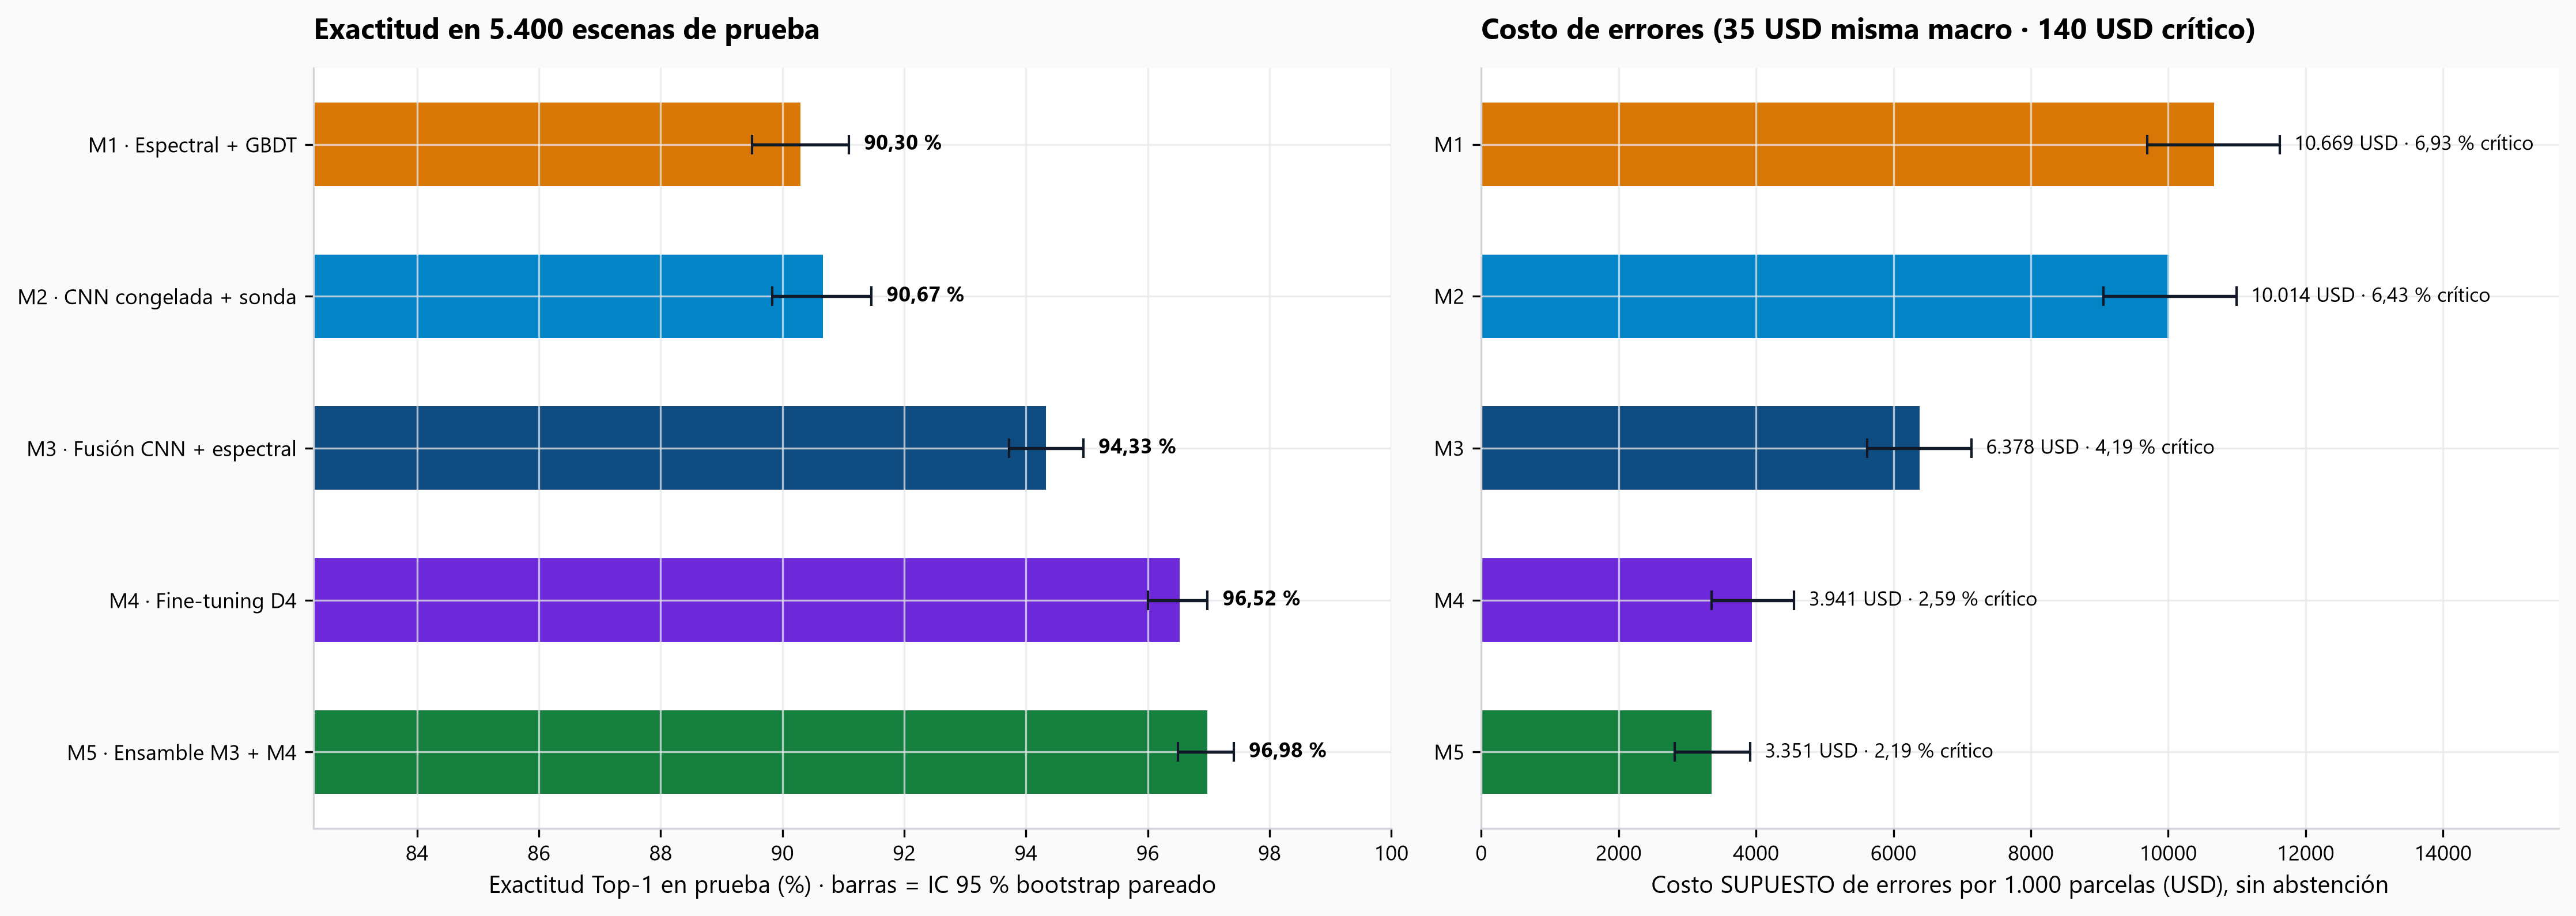

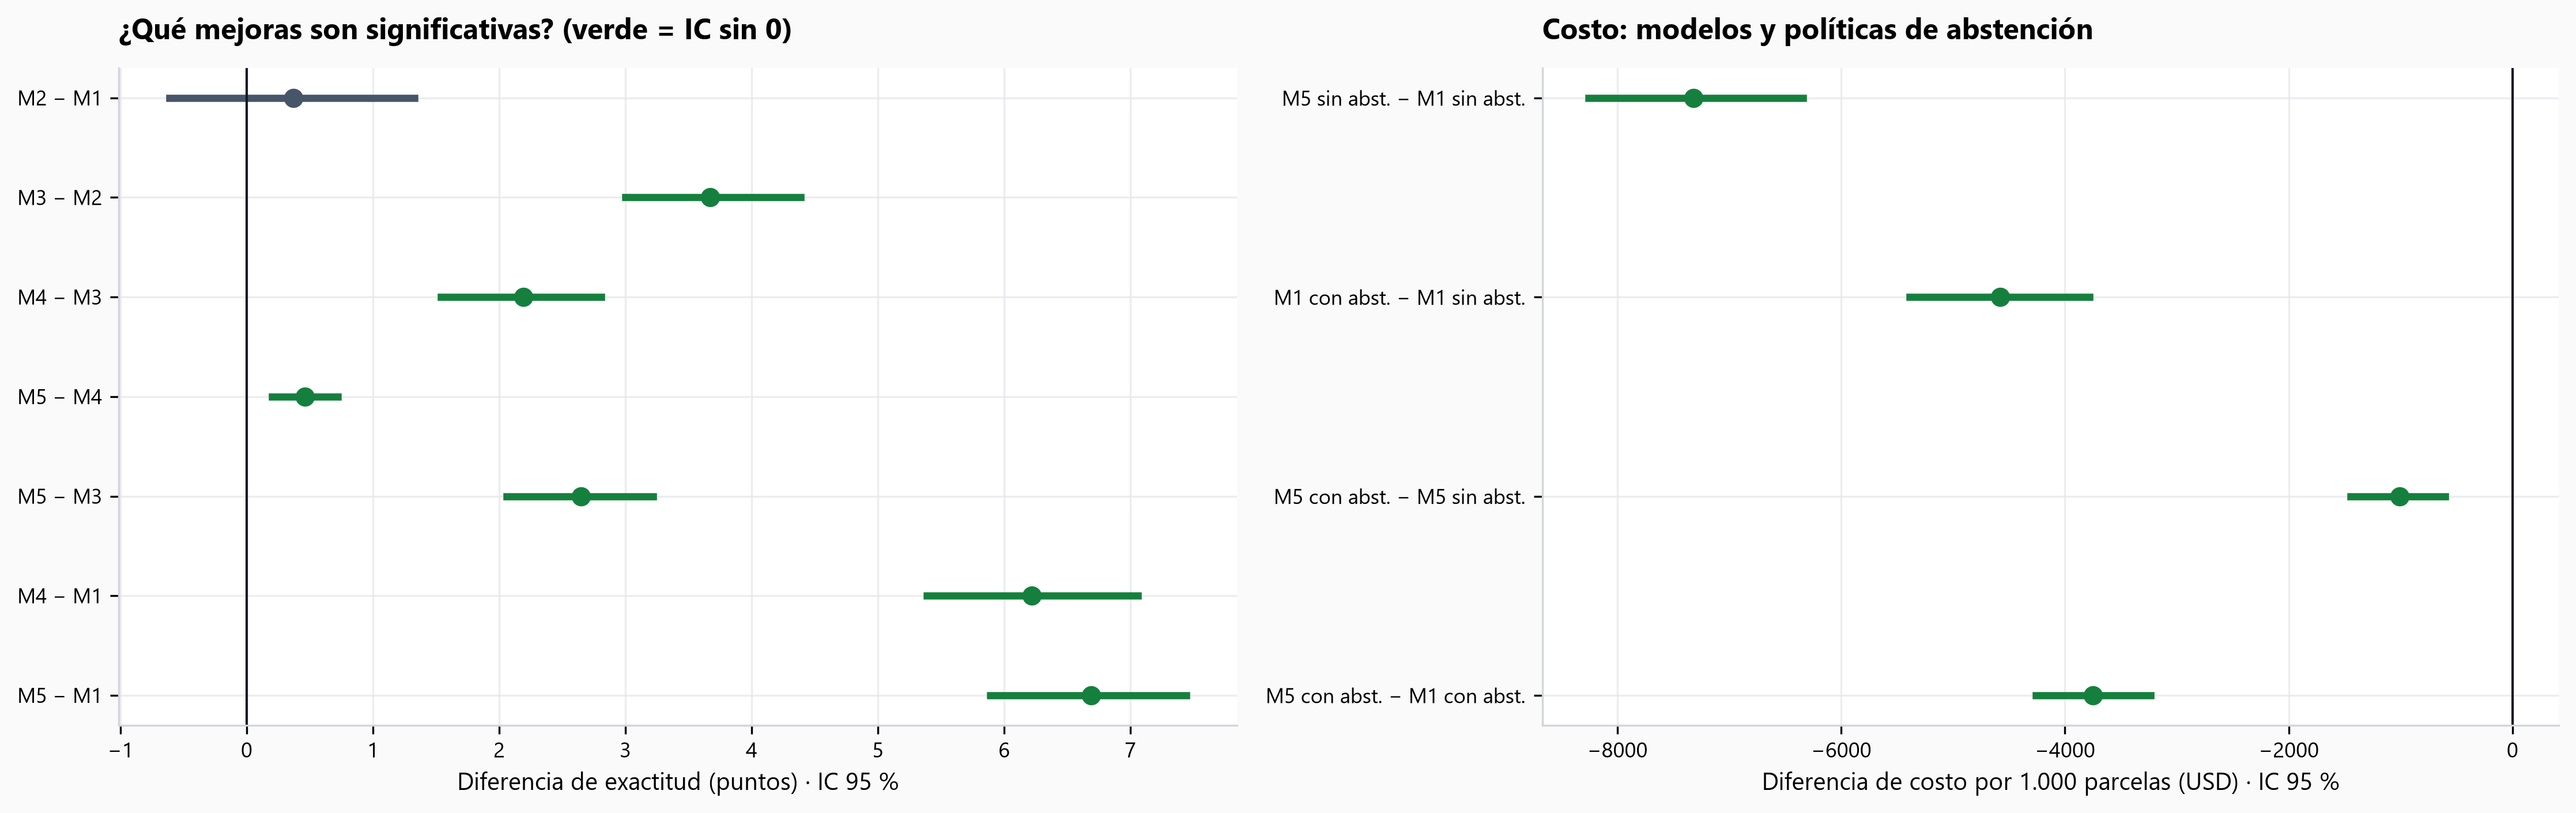

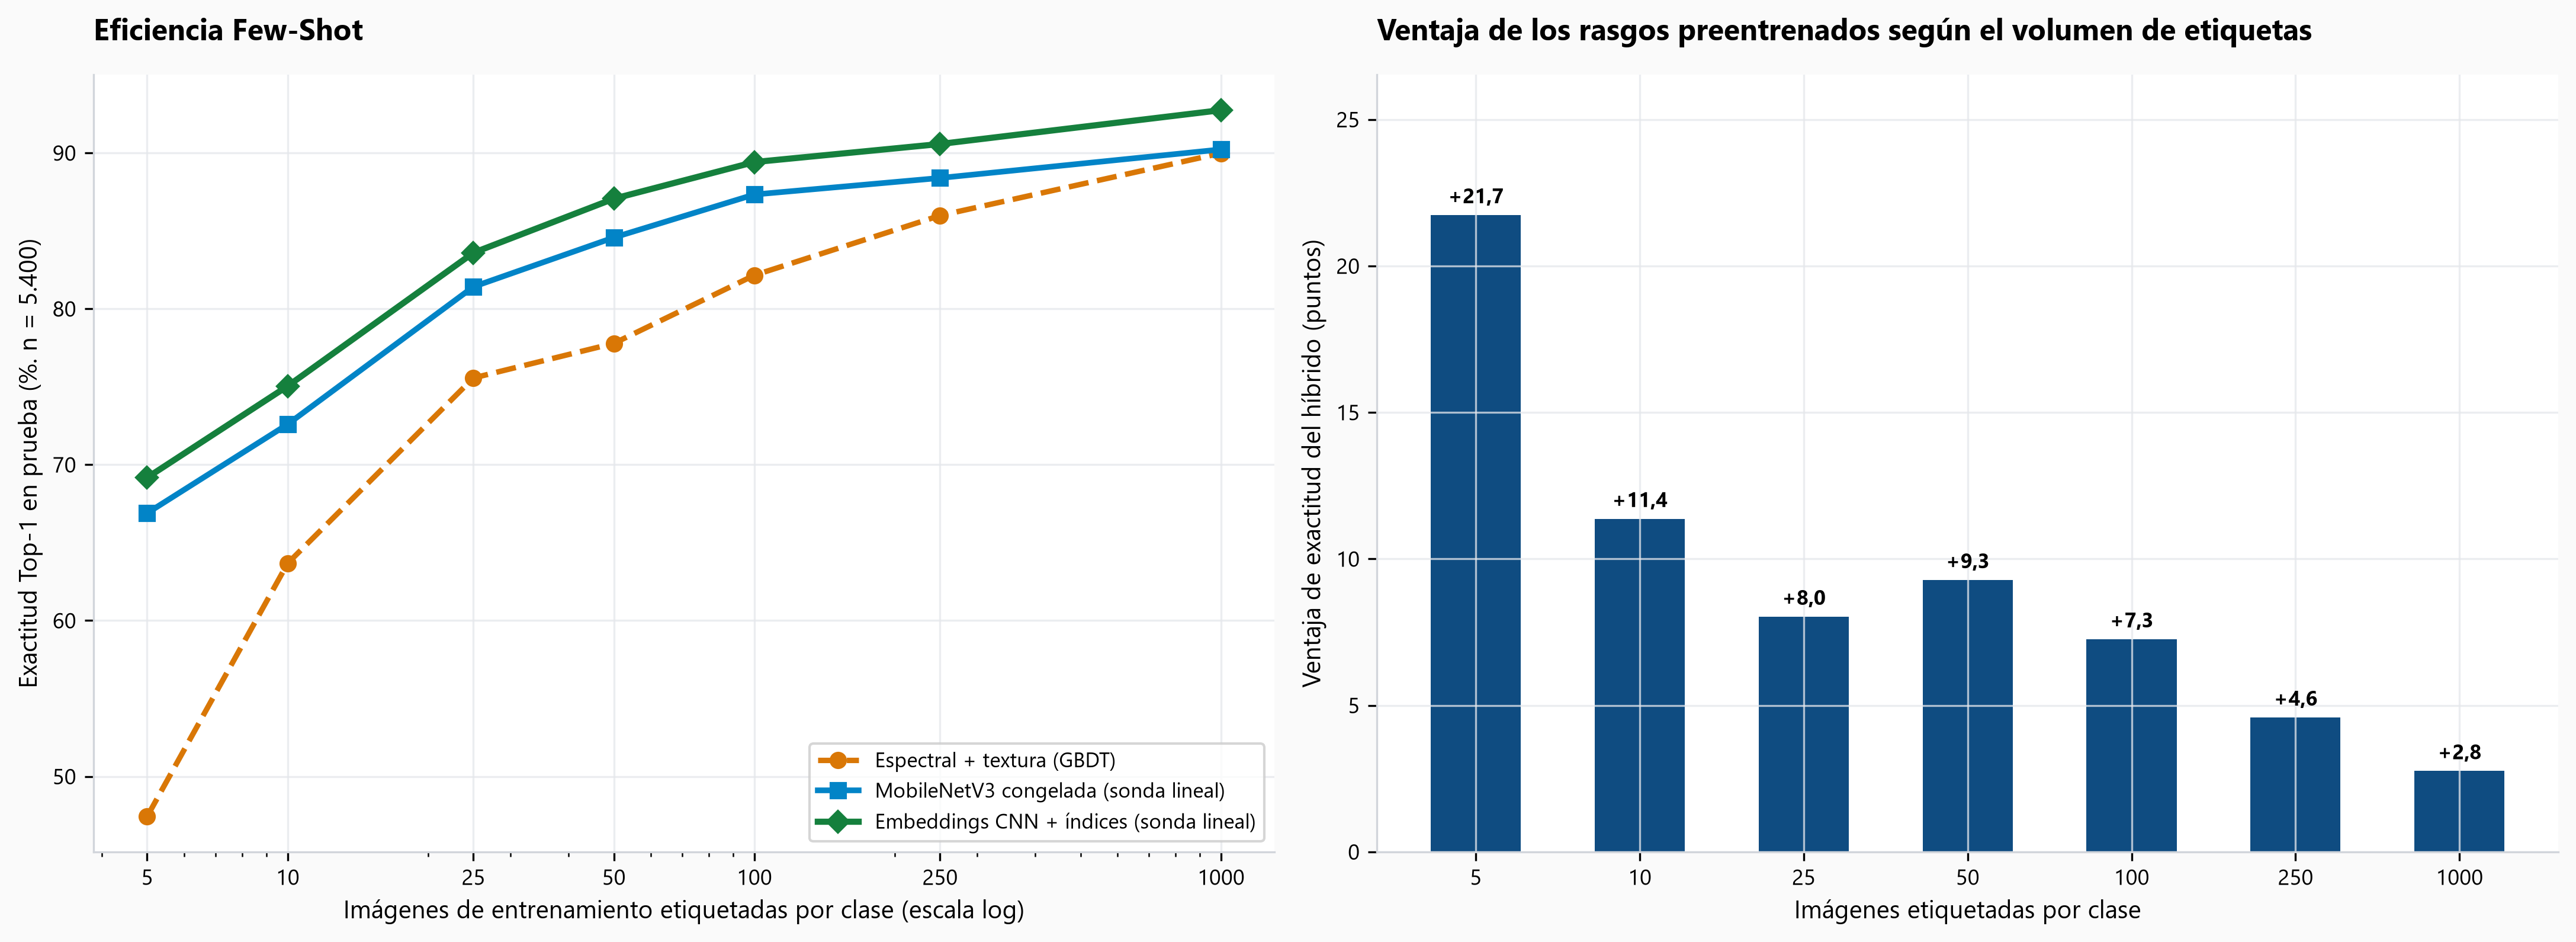

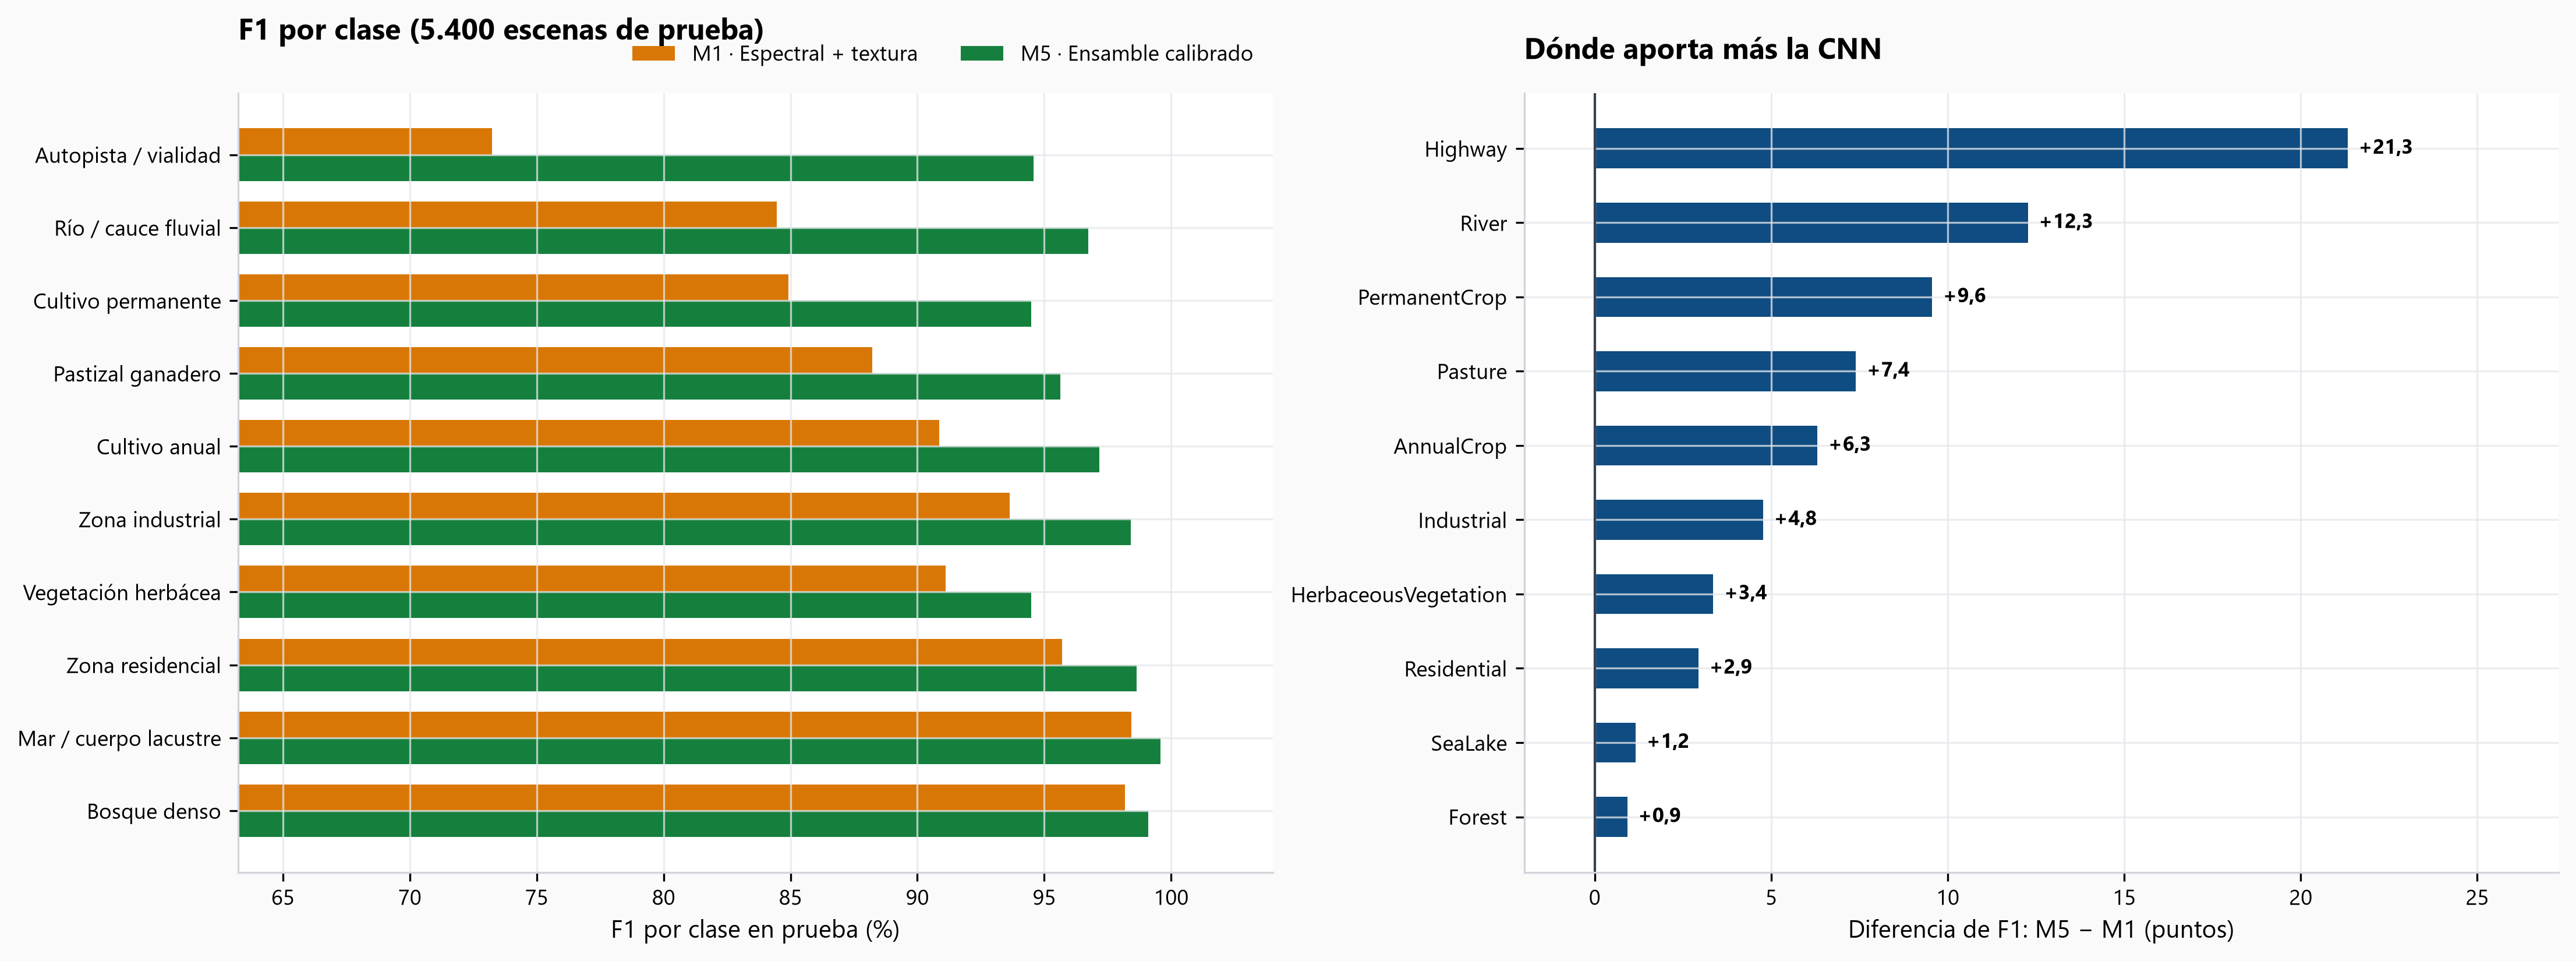

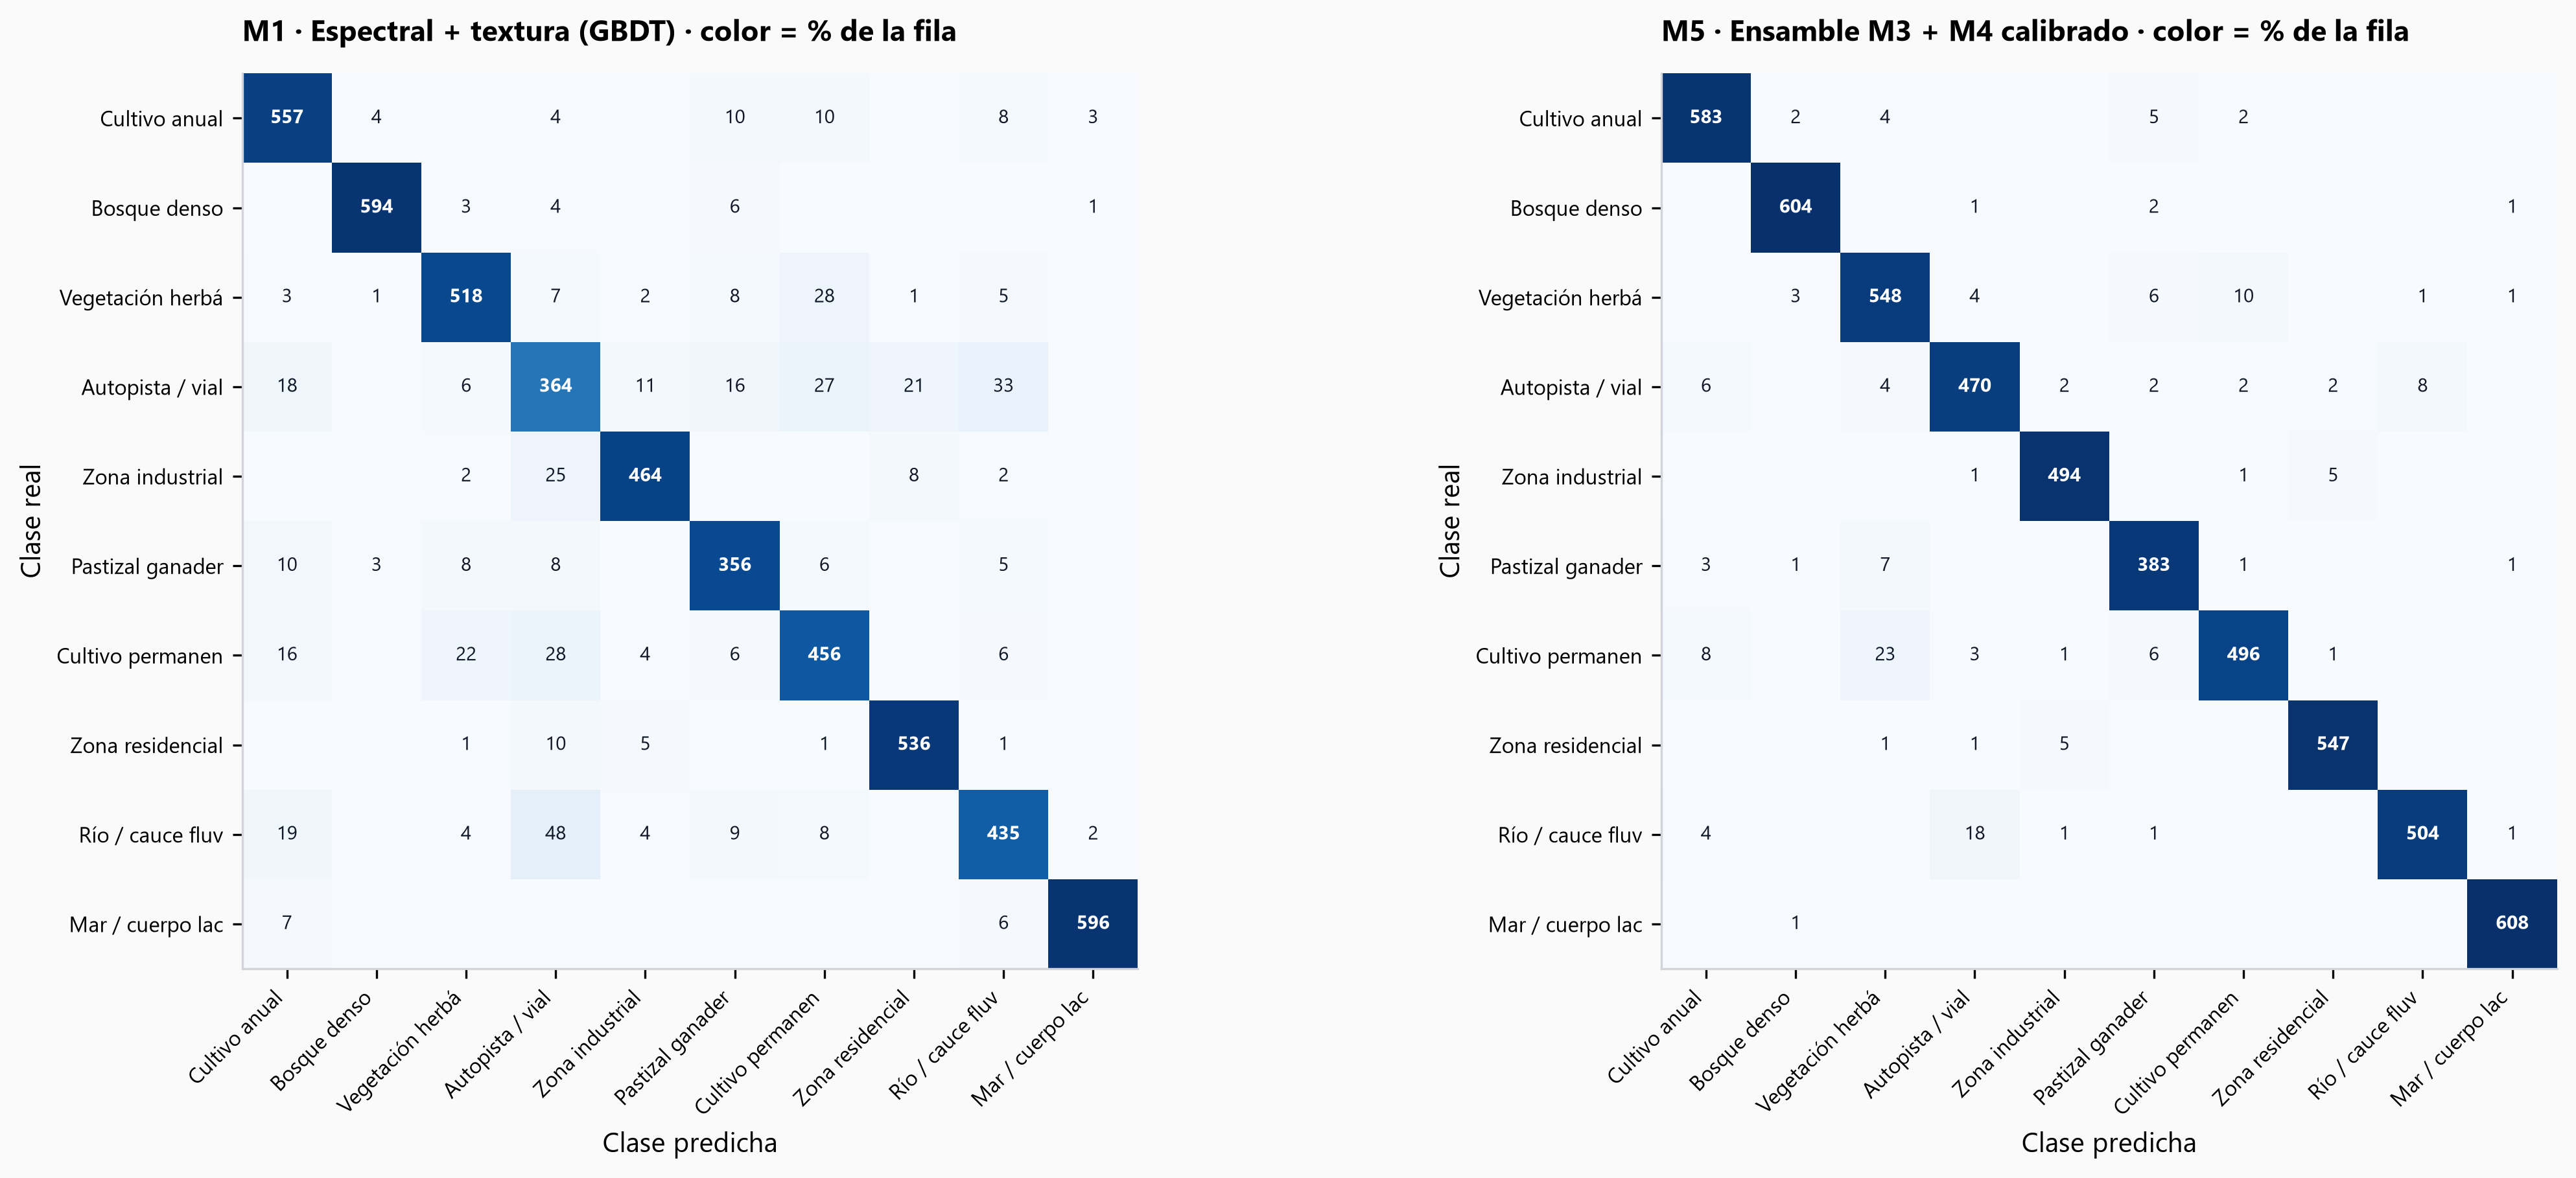

In [5]:
for f in ['02_comparacion_arquitecturas_cpu', '10_bootstrap_diferencias', '03_curva_few_shot_transfer_learning',
          '04_f1_por_clase_y_ganancia_transfer', '05_matrices_confusion_espectral_vs_transfer']:
    display(Image(f'reports/figures/{f}.png'))